# Anomaly Detection Tutorial

Anomaly Detection is a machine learning technique used to identify unusual patterns, rare events, or observations that differ significantly from normal data.

In this tutorial, we will learn:

- What anomaly detection is
- Where anomaly detection is used
- How to create a synthetic anomaly detection dataset
- How to train anomaly detection models in Python
- How to evaluate and visualize detected anomalies

We will implement three popular anomaly detection algorithms:

1. **Isolation Forest**
2. **Local Outlier Factor (LOF)**
3. **One-Class SVM**

## 1. What is Anomaly Detection?

Anomaly Detection is the process of finding data points that do not follow the expected behavior of the majority of the data.

These unusual data points are called:

- Anomalies
- Outliers
- Novel observations
- Abnormal samples

For example, in a credit card fraud detection system, most transactions are normal, but a very small number may be fraudulent. These rare fraudulent transactions are anomalies.

## 2. Applications of Anomaly Detection

Anomaly Detection is used in many real-world machine learning projects, including:

- **Fraud Detection:** Detecting suspicious financial transactions
- **Cybersecurity:** Identifying network intrusions or malicious traffic
- **Healthcare:** Detecting abnormal medical records or unusual patient conditions
- **Manufacturing:** Finding defective products or machine failures
- **Sensor Monitoring:** Detecting abnormal readings from IoT devices
- **Robotics and Industrial Safety:** Identifying unexpected objects, unsafe situations, or abnormal robot behavior

## 3. Import Required Libraries

We will use `scikit-learn` for models and metrics, `numpy` for numerical operations, and `matplotlib` for visualization.

In [3]:
%pip install matplotlib scikit-learn --quiet

Note: you may need to restart the kernel to use updated packages.


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

Matplotlib is building the font cache; this may take a moment.


## 4. Create a Synthetic Dataset

To make this tutorial easy to run, we will create a synthetic dataset instead of downloading an external dataset.

The dataset will contain:

- Normal samples generated from clusters
- Anomalous samples generated randomly far from the normal clusters

In anomaly detection, the anomalous class is usually much smaller than the normal class.

In [5]:
# Generate normal data
X_normal, _ = make_blobs(
    n_samples=1000,
    centers=2,
    n_features=2,
    cluster_std=1.2,
    random_state=RANDOM_STATE,
)

# Generate anomaly data
X_anomaly = np.random.uniform(low=-10, high=10, size=(80, 2))

# Combine normal and anomaly data
X = np.vstack([X_normal, X_anomaly])

# Labels: 0 = normal, 1 = anomaly
y = np.hstack([
    np.zeros(len(X_normal)),
    np.ones(len(X_anomaly))
])

# Create dataframe for easier visualization
df = pd.DataFrame(X, columns=["Feature_1", "Feature_2"])
df["Label"] = y.astype(int)

df.head()

,Feature_1,Feature_2,Label
0,-1.506367,7.658638,0
1,6.653120,1.308864,0
2,3.324349,0.245109,0
3,5.267281,1.284730,0
4,4.423303,5.804899,0


## 5. Visualize the Dataset

The normal points are expected to form clusters, while anomalies are expected to appear away from the normal data distribution.

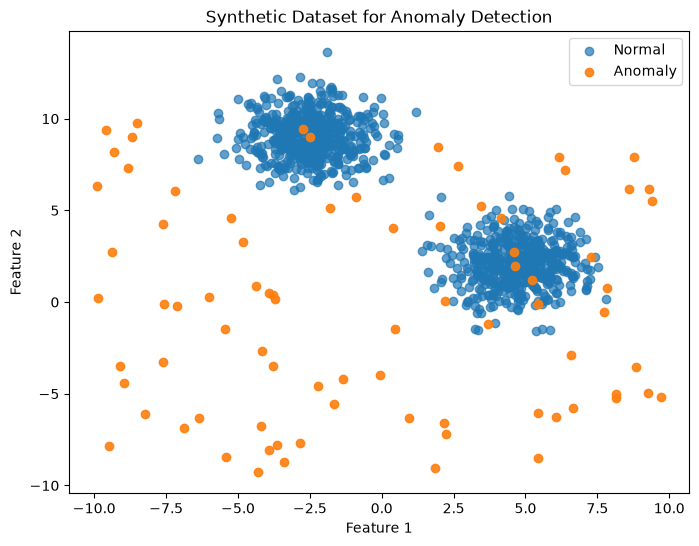

In [6]:
plt.figure(figsize=(8, 6))
plt.scatter(
    df[df["Label"] == 0]["Feature_1"],
    df[df["Label"] == 0]["Feature_2"],
    label="Normal",
    alpha=0.7,
)
plt.scatter(
    df[df["Label"] == 1]["Feature_1"],
    df[df["Label"] == 1]["Feature_2"],
    label="Anomaly",
    alpha=0.9,
)
plt.title("Synthetic Dataset for Anomaly Detection")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

## 6. Train-Test Split and Feature Scaling

We split the dataset into training and testing sets.

For this tutorial, we train models using the complete training split. In many real-world one-class anomaly detection settings, models are trained using only normal data. However, some algorithms can also estimate contamination when anomalies may exist in the training set.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=RANDOM_STATE,
    stratify=y,
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", X_train_scaled.shape[0])
print("Testing samples:", X_test_scaled.shape[0])
print("Anomaly ratio in test set:", y_test.mean())

Training samples: 756
Testing samples: 324
Anomaly ratio in test set: 0.07407407407407407


## 7. Helper Function for Evaluation

Different anomaly detection models return predictions in different formats.

In scikit-learn anomaly detection models:

- `1` usually means normal
- `-1` usually means anomaly

We convert this output to:

- `0` = normal
- `1` = anomaly

In [9]:
def convert_predictions(predictions):
    """Convert sklearn anomaly labels from {1, -1} to {0, 1}."""
    return np.where(predictions == -1, 1, 0)


def evaluate_model(model_name, y_true, y_pred, anomaly_scores=None):
    """Print evaluation results for an anomaly detection model."""
    print(f"===== {model_name} =====")
    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))
    print("Classification Report:")
    print(classification_report(y_true, y_pred, target_names=["Normal", "Anomaly"]))

    if anomaly_scores is not None:
        auc = roc_auc_score(y_true, anomaly_scores)
        print(f"ROC-AUC Score: {auc:.4f}")

## 8. Model 1: Isolation Forest

Isolation Forest is one of the most widely used anomaly detection algorithms.

The main idea is that anomalies are easier to isolate than normal points. The algorithm randomly splits the data and identifies points that require fewer splits to be isolated.

In [10]:
isolation_forest = IsolationForest(
    n_estimators=100,
    contamination=0.08,
    random_state=RANDOM_STATE,
)

isolation_forest.fit(X_train_scaled)

if_preds_raw = isolation_forest.predict(X_test_scaled)
if_preds = convert_predictions(if_preds_raw)

# decision_function gives higher values for normal samples, so we multiply by -1
if_scores = -isolation_forest.decision_function(X_test_scaled)

evaluate_model("Isolation Forest", y_test, if_preds, if_scores)

===== Isolation Forest =====
Confusion Matrix:
[[293   7]
 [  5  19]]
Classification Report:
              precision    recall  f1-score   support

      Normal       0.98      0.98      0.98       300
     Anomaly       0.73      0.79      0.76        24

    accuracy                           0.96       324
   macro avg       0.86      0.88      0.87       324
weighted avg       0.96      0.96      0.96       324

ROC-AUC Score: 0.9236


## 9. Model 2: Local Outlier Factor

Local Outlier Factor compares the local density of each data point with the density of its neighbors.

A point is considered anomalous if it has much lower density than its surrounding neighbors.

In [11]:
lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.08,
    novelty=True,
)

lof.fit(X_train_scaled)

lof_preds_raw = lof.predict(X_test_scaled)
lof_preds = convert_predictions(lof_preds_raw)

# decision_function gives higher values for normal samples, so we multiply by -1
lof_scores = -lof.decision_function(X_test_scaled)

evaluate_model("Local Outlier Factor", y_test, lof_preds, lof_scores)

===== Local Outlier Factor =====
Confusion Matrix:
[[290  10]
 [ 10  14]]
Classification Report:
              precision    recall  f1-score   support

      Normal       0.97      0.97      0.97       300
     Anomaly       0.58      0.58      0.58        24

    accuracy                           0.94       324
   macro avg       0.78      0.78      0.78       324
weighted avg       0.94      0.94      0.94       324

ROC-AUC Score: 0.8325


## 10. Model 3: One-Class SVM

One-Class SVM learns a boundary around normal data points. Points outside this boundary are considered anomalies.

This method can work well when normal data follows a compact distribution, but it can be sensitive to hyperparameters such as `nu` and `gamma`.

In [12]:
one_class_svm = OneClassSVM(
    kernel="rbf",
    gamma="scale",
    nu=0.08,
)

one_class_svm.fit(X_train_scaled)

svm_preds_raw = one_class_svm.predict(X_test_scaled)
svm_preds = convert_predictions(svm_preds_raw)

# decision_function gives higher values for normal samples, so we multiply by -1
svm_scores = -one_class_svm.decision_function(X_test_scaled)

evaluate_model("One-Class SVM", y_test, svm_preds, svm_scores)

===== One-Class SVM =====
Confusion Matrix:
[[292   8]
 [  7  17]]
Classification Report:
              precision    recall  f1-score   support

      Normal       0.98      0.97      0.97       300
     Anomaly       0.68      0.71      0.69        24

    accuracy                           0.95       324
   macro avg       0.83      0.84      0.83       324
weighted avg       0.95      0.95      0.95       324

ROC-AUC Score: 0.9364


## 11. Visualize Model Predictions

Now we visualize the anomalies detected by each model.

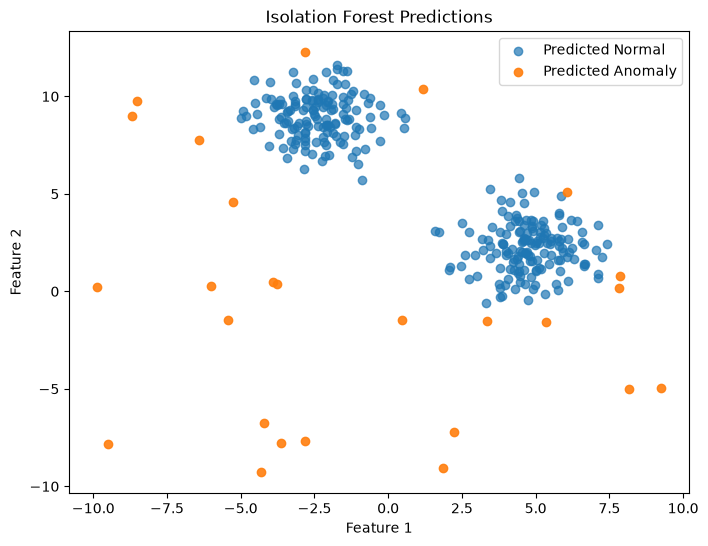

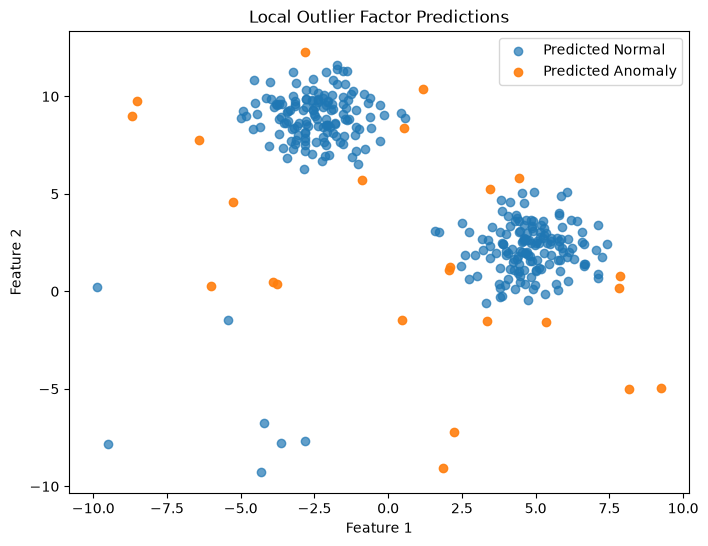

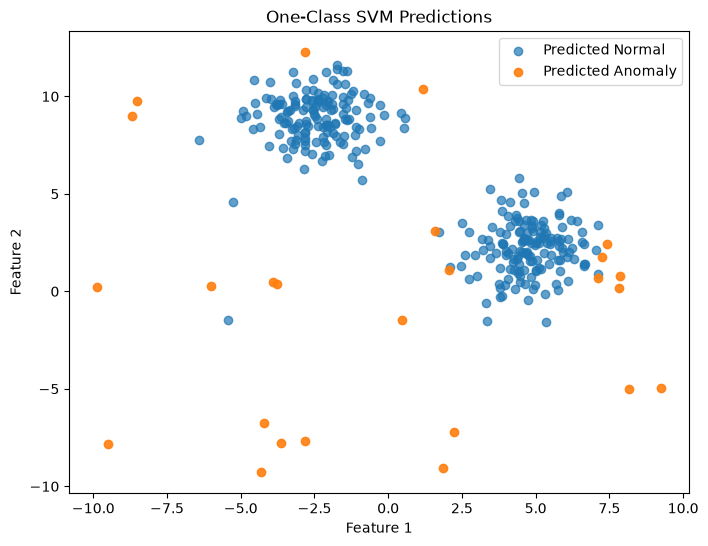

In [13]:
def plot_predictions(X_data, y_pred, title):
    plt.figure(figsize=(8, 6))
    plt.scatter(
        X_data[y_pred == 0, 0],
        X_data[y_pred == 0, 1],
        label="Predicted Normal",
        alpha=0.7,
    )
    plt.scatter(
        X_data[y_pred == 1, 0],
        X_data[y_pred == 1, 1],
        label="Predicted Anomaly",
        alpha=0.9,
    )
    plt.title(title)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.legend()
    plt.show()

# Convert scaled test data back to original feature space for easier visualization
X_test_original = scaler.inverse_transform(X_test_scaled)

plot_predictions(X_test_original, if_preds, "Isolation Forest Predictions")
plot_predictions(X_test_original, lof_preds, "Local Outlier Factor Predictions")
plot_predictions(X_test_original, svm_preds, "One-Class SVM Predictions")

## 12. Compare ROC-AUC Scores

ROC-AUC measures how well the anomaly score separates normal samples from anomalous samples.

A higher ROC-AUC value means better separation between normal and anomalous examples.

In [14]:
results = pd.DataFrame({
    "Model": ["Isolation Forest", "Local Outlier Factor", "One-Class SVM"],
    "ROC-AUC": [
        roc_auc_score(y_test, if_scores),
        roc_auc_score(y_test, lof_scores),
        roc_auc_score(y_test, svm_scores),
    ],
})

results

,Model,ROC-AUC
0,Isolation Forest,0.923611
1,Local Outlier Factor,0.832500
2,One-Class SVM,0.936389


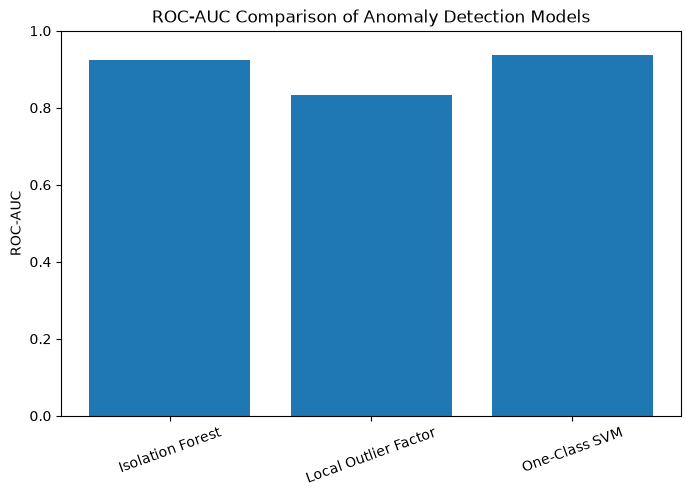

In [15]:
plt.figure(figsize=(8, 5))
plt.bar(results["Model"], results["ROC-AUC"])
plt.title("ROC-AUC Comparison of Anomaly Detection Models")
plt.ylabel("ROC-AUC")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.show()

## 13. Key Takeaways

In this tutorial, we learned that:

- Anomaly Detection is used to identify rare or unusual data points.
- It is useful in fraud detection, cybersecurity, healthcare, manufacturing, and industrial safety.
- Isolation Forest detects anomalies by isolating unusual samples.
- Local Outlier Factor detects anomalies based on local density differences.
- One-Class SVM learns a boundary around normal data.
- Evaluation can be performed using confusion matrix, classification report, and ROC-AUC.

## 14. Next Steps

To extend this tutorial, you can try:

- Using a real-world dataset such as credit card fraud detection
- Training only on normal samples for a stricter one-class setup
- Tuning hyperparameters such as `contamination`, `n_neighbors`, and `nu`
- Applying anomaly detection to images, time series, or network traffic data